# **Problem Statement:**

Imagine you are a crciket coach of Indian Cricekt Team and you have stats of 100 Players. You want to group players with similar abilities so that you can select players for different match staretigies.

Our goal is to group players with similar performance characteristics into clusters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/Cricket.csv",encoding='latin')
#read_csv, by default takes utf-8 encoded manner. this is not in utf-8. this is in latin.
#hence, we change the encoding by passing it as the parameter
#just use them one by one until we dont get any errors
#latin1,ISO-8859-1,cp1252

In [3]:
df

,Player,Span,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0
0,SR Tendulkar (INDIA),1989-2012,463,452,41,18426,200*,44.83,21367,86.23,49,96,20
1,KC Sangakkara (Asia/ICC/SL),2000-2015,404,380,41,14234,169,41.98,18048,78.86,25,93,15
2,RT Ponting (AUS/ICC),1995-2012,375,365,39,13704,164,42.03,17046,80.39,30,82,20
3,ST Jayasuriya (Asia/SL),1989-2011,445,433,18,13430,189,32.36,14725,91.20,28,68,34
4,DPMD Jayawardene (Asia/SL),1998-2015,448,418,39,12650,144,33.37,16020,78.96,19,77,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),1975-1991,128,127,13,5134,133*,45.03,7908,64.92,11,31,3
75,Misbah-ul-Haq (PAK),2002-2015,162,149,31,5122,96*,43.40,6945,73.75,0,42,6
76,PD Collingwood (ENG),2001-2011,197,181,37,5092,120*,35.36,6614,76.98,5,26,7
77,A Symonds (AUS),1998-2009,198,161,33,5088,156,39.75,5504,92.44,6,30,15


#Columns description:
1.Player: Name

2.Span : Years active

3.Mat : No of matches

4.Inns: Total Innings

5.NO : Not Out matches

6.Runs : Total runs scored

7.HS : Highest Score

8.Ave : Average

9.BF : Balls Faced

10.SR : Strike Rate

11.100 : Centuries

12.50 : Half Centuries

13.0 : Zeroes

In [4]:
#EDA
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  79 non-null     object 
 1   Span    79 non-null     object 
 2   Mat     79 non-null     int64  
 3   Inns    79 non-null     int64  
 4   NO      79 non-null     int64  
 5   Runs    79 non-null     int64  
 6   HS      79 non-null     object 
 7   Ave     79 non-null     float64
 8   BF      79 non-null     int64  
 9   SR      79 non-null     float64
 10  100     79 non-null     int64  
 11  50      79 non-null     int64  
 12  0       79 non-null     int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 8.2+ KB


In [5]:
#Span -> String
#but K-Means takes only numerical values
#=> extraxt the start and end years, and then subtract

In [6]:
df[['start','end']]=df['Span'].str.split('-',expand=True)
#we gave a list of new columns being create
#using a string function split on the basis of separator
#expand=True -> makes the two extracted strings fit into separate columns, start and end
#if we didnt have expand -> both years will be stored in the same column

In [7]:
df

,Player,Span,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,start,end
0,SR Tendulkar (INDIA),1989-2012,463,452,41,18426,200*,44.83,21367,86.23,49,96,20,1989,2012
1,KC Sangakkara (Asia/ICC/SL),2000-2015,404,380,41,14234,169,41.98,18048,78.86,25,93,15,2000,2015
2,RT Ponting (AUS/ICC),1995-2012,375,365,39,13704,164,42.03,17046,80.39,30,82,20,1995,2012
3,ST Jayasuriya (Asia/SL),1989-2011,445,433,18,13430,189,32.36,14725,91.20,28,68,34,1989,2011
4,DPMD Jayawardene (Asia/SL),1998-2015,448,418,39,12650,144,33.37,16020,78.96,19,77,28,1998,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),1975-1991,128,127,13,5134,133*,45.03,7908,64.92,11,31,3,1975,1991
75,Misbah-ul-Haq (PAK),2002-2015,162,149,31,5122,96*,43.40,6945,73.75,0,42,6,2002,2015
76,PD Collingwood (ENG),2001-2011,197,181,37,5092,120*,35.36,6614,76.98,5,26,7,2001,2011
77,A Symonds (AUS),1998-2009,198,161,33,5088,156,39.75,5504,92.44,6,30,15,1998,2009


In [8]:
#start and end are still strings -> convert into int
df['start']=df['start'].astype('int')
df['end']=df['end'].astype('int')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  79 non-null     object 
 1   Span    79 non-null     object 
 2   Mat     79 non-null     int64  
 3   Inns    79 non-null     int64  
 4   NO      79 non-null     int64  
 5   Runs    79 non-null     int64  
 6   HS      79 non-null     object 
 7   Ave     79 non-null     float64
 8   BF      79 non-null     int64  
 9   SR      79 non-null     float64
 10  100     79 non-null     int64  
 11  50      79 non-null     int64  
 12  0       79 non-null     int64  
 13  start   79 non-null     int64  
 14  end     79 non-null     int64  
dtypes: float64(2), int64(10), object(3)
memory usage: 9.4+ KB


In [10]:
#creating an experience column
df['exp']=df['end']-df['start']

In [11]:
#now we dont need start, end and span -> drop them
df.drop(['start','end','Span'],axis=1,inplace=True)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  79 non-null     object 
 1   Mat     79 non-null     int64  
 2   Inns    79 non-null     int64  
 3   NO      79 non-null     int64  
 4   Runs    79 non-null     int64  
 5   HS      79 non-null     object 
 6   Ave     79 non-null     float64
 7   BF      79 non-null     int64  
 8   SR      79 non-null     float64
 9   100     79 non-null     int64  
 10  50      79 non-null     int64  
 11  0       79 non-null     int64  
 12  exp     79 non-null     int64  
dtypes: float64(2), int64(9), object(2)
memory usage: 8.2+ KB


In [13]:
#now, HS is also in string -> convert
#for this, we cant use astype as there are not out stars mentioned in the data set
#astype requires as numbers to get converted

In [14]:
#we can replace the stars with empty strings
df['HS']=df['HS'].str.replace("*","")

In [15]:
#now convert into int
df['HS']=df['HS'].astype('int')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  79 non-null     object 
 1   Mat     79 non-null     int64  
 2   Inns    79 non-null     int64  
 3   NO      79 non-null     int64  
 4   Runs    79 non-null     int64  
 5   HS      79 non-null     int64  
 6   Ave     79 non-null     float64
 7   BF      79 non-null     int64  
 8   SR      79 non-null     float64
 9   100     79 non-null     int64  
 10  50      79 non-null     int64  
 11  0       79 non-null     int64  
 12  exp     79 non-null     int64  
dtypes: float64(2), int64(10), object(1)
memory usage: 8.2+ KB


In [17]:
#all numbers except playner name -> we cant convert name into number so its okay

In [18]:
df.duplicated().sum()
#no duplicates

np.int64(0)

In [19]:
df.isna().sum()

,0
Player,0
Mat,0
Inns,0
NO,0
Runs,0
HS,0
Ave,0
BF,0
SR,0
100,0


In [20]:
#outliers are not needed to be checked -> outliers represent exceptional performance
#removing outlier players -> removing star players -> losing data

In [21]:
#now, we create a copy of the dataset -> w/o names to give to model and the original
# to identify stats and the player with those stats

In [22]:
df_copy=df.copy()

In [23]:
df_copy.drop('Player',axis=1,inplace=True)

#Standardization/Scaling

Technique used to scale the numerical data.
Different columns have different ranges. Features having large values or large ranges influence the model and dominate over the others. This makes the predictions biased towards the larger values(output takes the larger value feature into maximum consideration and it overrules the other, but equally importnat features)


Scaled Value = (Value-Mean)/Standard Deviation

In [24]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [25]:
df_scaled=scaler.fit_transform(df_copy)
df_scaled

array([[ 2.95528204e+00,  3.16933340e+00,  7.64962749e-01,
         4.26232808e+00,  1.63244320e+00,  1.07229395e+00,
         3.68121424e+00,  7.03151526e-01,  4.65672622e+00,
         3.05005720e+00,  1.14583653e+00,  2.81278702e+00],
       [ 2.15517925e+00,  2.13891509e+00,  7.64962749e-01,
         2.60911662e+00,  6.35223595e-01,  5.87724608e-01,
         2.63538469e+00, -4.41394951e-02,  1.67188751e+00,
         2.86541772e+00,  2.96670622e-01,  3.80938324e-01],
       [ 1.76190839e+00,  1.92424461e+00,  6.25396797e-01,
         2.40009894e+00,  4.74381724e-01,  5.96225824e-01,
         2.31965067e+00,  1.10996904e-01,  2.29372891e+00,
         2.18840630e+00,  1.14583653e+00,  9.88900497e-01],
       [ 2.71118288e+00,  2.89741746e+00, -8.40045698e-01,
         2.29204075e+00,  1.27859108e+00, -1.04790945e+00,
         1.58829472e+00,  1.20709133e+00,  2.04499235e+00,
         1.32675540e+00,  3.52350108e+00,  2.50880593e+00],
       [ 2.75186607e+00,  2.68274698e+00,  6.2539679

In [26]:
#retured as an array -> convert into a data frame
#df_scaled=pd.DataFrame(df_scaled)

In [27]:
#df_scaled

In [28]:
#we're not getting column names -> mention columns
df_scaled=pd.DataFrame(df_scaled,columns=df_copy.columns)

In [29]:
df_scaled

,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,exp
0,2.955282,3.169333,0.764963,4.262328,1.632443,1.072294,3.681214,0.703152,4.656726,3.050057,1.145837,2.812787
1,2.155179,2.138915,0.764963,2.609117,0.635224,0.587725,2.635385,-0.044139,1.671888,2.865418,0.296671,0.380938
2,1.761908,1.924245,0.625397,2.400099,0.474382,0.596226,2.319651,0.110997,2.293729,2.188406,1.145837,0.988900
3,2.711183,2.897417,-0.840046,2.292041,1.278591,-1.047909,1.588295,1.207091,2.044992,1.326755,3.523501,2.508806
4,2.751866,2.682747,0.625397,1.984430,-0.168986,-0.876185,1.996354,-0.034000,0.925678,1.880674,2.504502,0.988900
...,...,...,...,...,...,...,...,...,...,...,...,...
74,-1.587674,-1.481860,-1.188961,-0.979677,-0.522838,1.106299,-0.559768,-1.457604,-0.069268,-0.950465,-1.741328,0.684919
75,-1.126598,-1.167010,0.067133,-0.984410,-1.713068,0.829159,-0.863213,-0.562275,-1.437319,-0.273453,-1.231828,-0.227024
76,-0.651961,-0.709047,0.485831,-0.996241,-0.941027,-0.537836,-0.967512,-0.234765,-0.815478,-1.258197,-1.061995,-1.138967
77,-0.638400,-0.995274,0.206699,-0.997819,0.217035,0.208570,-1.317278,1.332823,-0.691110,-1.012011,0.296671,-0.834986


#Model Building

In [30]:
from sklearn.cluster import KMeans

In [31]:
'''How to choose the k value?
for a smaller dataset(2000 rows), we can try values upto 10 for k.
For a large data set, we can try 30 or n/10, where n -> number of rows'''

'How to choose the k value?\nfor a smaller dataset(2000 rows), we can try values upto 10 for k.\nFor a large data set, we can try 30 or n/10, where n -> number of rows'

In [32]:
k=[2,3,4,5,6,7,8,9,10]
#Within Cluster Sum of Sqaured Distance / Total Within Cluster Variation
#is calculated for each k and we find the best k using the elbow method

In [33]:
#create a list for WCSS/TWCV
wcss=[]
#for every k, build the model and test the wcss
for i in k:
  km=KMeans(n_clusters=i,random_state=42) #making a model with i cluster and
  #random state to lock in the random selection
  km.fit(df_scaled)
  wcss.append(km.inertia_) #wcss aka inertia_
wcss

[644.840516217269,
 586.2725236030707,
 474.16095045677974,
 439.53342325958914,
 388.9283315814862,
 336.01686079526297,
 325.9967390992313,
 294.15769727462543,
 283.8579208648257]

**Within a single loop iteration (i)**: n_init forces the algorithm to use different initial points for each internal run to thoroughly sample the space.

**Across different executions of your script**: random_state ensures that this exact variation is reproduced identically, guaranteeing that you and a colleague get the same elbow graph.

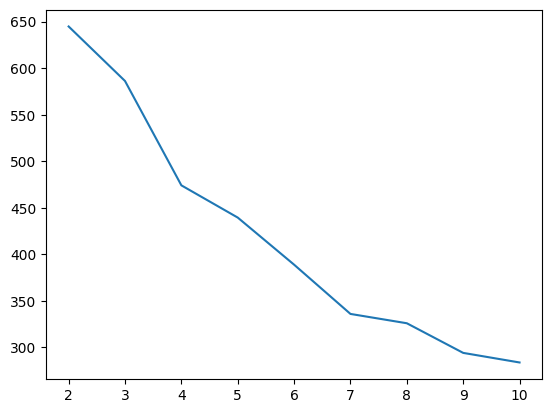

In [34]:
#now, plot them to select k using the elbow method
plt.plot(k,wcss)

In [35]:
#just by looking at it, we're not able to choose a single k
#maybe 4,5,7 -> elbow points
#we're getting a range of k values

In [36]:
#to get the optimal k value in such situations, we use silhouttee score

# **Silhouttee Score:**


Silhouttee Score(Metric) : It is a metric used to evaluate how good the clustering is.

or

How well each data point fits inside its own cluster and how far it is from other clusters

For Every k _value it will give a score which is between 1 to -1

Near +1             :   Excellent clusterig

Around 0            :   Overlapping clusters

Near -1             :   Incorrect clustering


s = (b-a)/max(a,b)

a = Intra-Cluster Distance

Average distance of a point from other points in the same cluster

b = Inter-Cluster  Distance

Average Distance from points in the Nearest other cluster.


Case 1: Good  Cluster

a=2, b=10

s=10-2/max(2,10)

  =8/10
 =0.8   (closer to 1)


 Case 2: Overlapping Cluster

a=5, b=5

s=5-5/max(5,5)
  s=0


Case 3: Wrong Clustering

a=8, b=3

s=3-8/max(3,8)
 =-5/8
 =-0.6

In [37]:
#now importing silhoutee score from metric
from sklearn.metrics import silhouette_score
score=[] #empty list for the scores
for i in k:
  km=KMeans(n_clusters=i,random_state=42)  # for each k, make a kmeans model
  km.fit(df_scaled)
  score_avg=silhouette_score(df_scaled,km.labels_)
  #calculate score for each k model
  score.append(score_avg) #append to the empty list

In [ ]:
# km.labels_ contains the cluster assignment for every data point after K-Means clustering.
# silhouette_score() uses these labels to evaluate the quality of clustering.
# It measures how similar each point is to its own cluster (cohesion)
# compared to other clusters (separation).
# Higher silhouette score indicates better-defined and well-separated clusters.

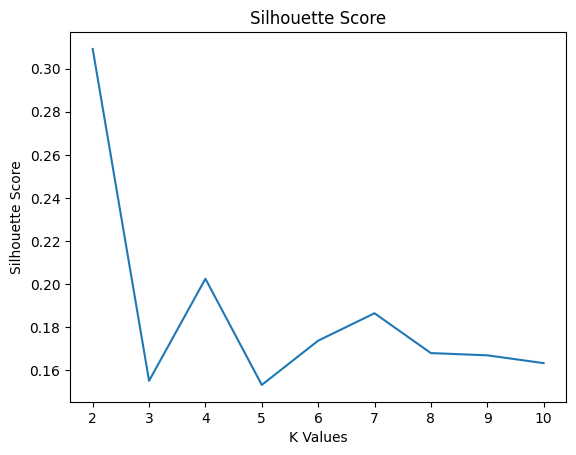

In [39]:
plt.plot(k,score)
plt.title("Silhouette Score")
plt.xlabel("K Values")
plt.ylabel("Silhouette Score")
plt.show()

In [ ]:
#1. From the Elbow method, we find the RANGE of k values we need
#2. Among them, to choose the optimum k, calculate silhouette scores and choose the k
# which has the maximum score(closest to +1)

In [ ]:
#now, from the above, 4,5,7 are the possible k values -> out of these, 4 has highest score
# Hence, k=4 is the optimum k value

In [40]:
kmeans=KMeans(n_clusters=4,random_state=42)
kmeans.fit(df_scaled)
#we built the best model

KMeans(n_clusters=4, random_state=42)

In [41]:
#now, we look at the labels or clusters assigned
kmeans.labels_
#0,1,2,3 -> total 4

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 0, 3, 0, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 0, 3, 3, 3, 0, 3, 3, 3, 3, 0, 3, 1, 1, 0, 1, 1, 3, 0, 3,
       3, 3, 0, 1, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3], dtype=int32)

In [42]:
#now, to the original dataframe, added the cluster id to represent their group/cluster
df['clusterID']=kmeans.labels_

In [43]:
df

,Player,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,exp,clusterID
0,SR Tendulkar (INDIA),463,452,41,18426,200,44.83,21367,86.23,49,96,20,23,2
1,KC Sangakkara (Asia/ICC/SL),404,380,41,14234,169,41.98,18048,78.86,25,93,15,15,2
2,RT Ponting (AUS/ICC),375,365,39,13704,164,42.03,17046,80.39,30,82,20,17,2
3,ST Jayasuriya (Asia/SL),445,433,18,13430,189,32.36,14725,91.20,28,68,34,22,2
4,DPMD Jayawardene (Asia/SL),448,418,39,12650,144,33.37,16020,78.96,19,77,28,17,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),128,127,13,5134,133,45.03,7908,64.92,11,31,3,16,1
75,Misbah-ul-Haq (PAK),162,149,31,5122,96,43.40,6945,73.75,0,42,6,13,1
76,PD Collingwood (ENG),197,181,37,5092,120,35.36,6614,76.98,5,26,7,10,1
77,A Symonds (AUS),198,161,33,5088,156,39.75,5504,92.44,6,30,15,11,1


In [44]:
group1=df[df['clusterID']==1]
group1
#separate dataframes for each cluster

,Player,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,exp,clusterID
36,NJ Astle (NZ),223,217,14,7090,145,34.92,9760,72.64,16,41,19,12,1
37,GC Smith (Afr/SA),197,194,10,6989,141,37.98,8648,80.81,10,47,8,11,1
39,G Kirsten (SA),185,185,19,6798,188,40.95,9436,72.04,13,45,11,10,1
40,A Flower (ZIM),213,208,16,6786,145,35.34,9097,74.59,4,55,13,11,1
47,RB Richardson (WI),224,217,30,6248,122,33.41,9801,63.74,5,44,8,13,1
48,WU Tharanga (Asia/SL),204,193,14,6140,174,34.30,8183,75.03,14,34,15,12,1
49,ML Hayden (AUS/ICC),161,155,15,6133,181,43.80,7767,78.96,10,36,9,15,1
51,DM Jones (AUS),164,161,25,6068,145,44.61,8362,72.56,7,46,6,10,1
52,DC Boon (AUS),181,177,16,5964,122,37.04,9157,65.13,5,37,6,11,1
53,JN Rhodes (SA),245,220,51,5935,121,35.11,7336,80.90,2,33,12,11,1


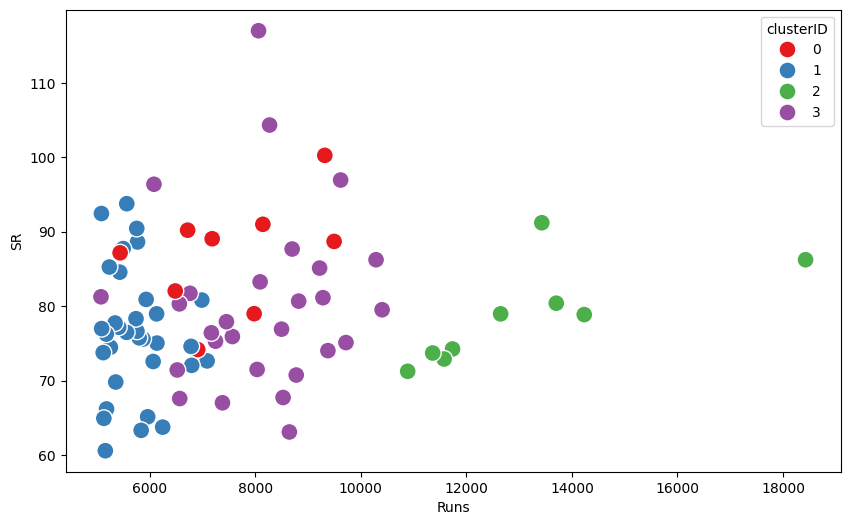

In [46]:
#now, to know how each cluster is formed, we can visualize using a graph
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Runs',y='SR',hue='clusterID',palette='Set1',s=150)
plt.show()

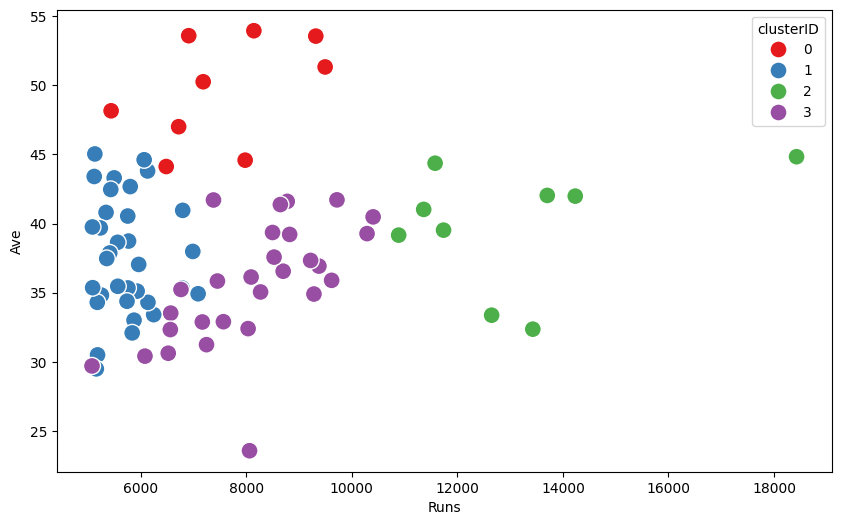

In [47]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Runs',y='Ave',hue='clusterID',palette='Set1',s=150) #s -> size
plt.show()

In [48]:
#for 3d plots, we do the following
!pip install plotly

In [49]:
import plotly.express as px

In [51]:
#Create a 3d scatter plot
fig=px.scatter_3d(df,x='Runs',y='Ave',z='SR',color='clusterID',hover_data='Player',title='3d Scatter Plot of cricketer')

#hover_data :  hover_data='Player' shows the player name when hovering over a point.
# Without it, only the plotted values (Runs, Ave, SR, ClusterID) are shown.

#Change layout
fig.update_layout(scene=dict(xaxis_title='Runs',yaxis_title='Average',zaxis_title='Strike Rate'),width=800,height=600)
# scene represents the 3D plot area, and dict() contains settings to customize its axes.

fig.show()